In [35]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

np.random.seed(20)

In [36]:
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2)**2))

In [37]:
class KMeans():
    def __init__(self, K, max_iters=100, plot_steps=False, random_state=272):
        self.K = K
        self.max_iters = max_iters
        self.plot_steps = plot_steps
        self.fig_number = 0
        self.random_state = random_state
        self.clusters = [[] for _ in range(self.K)]
        self.centroids = None

    def fit(self, X):
        self.X = X
        self.n_samples, self.n_features = X.shape

        # K-Means++ initialization
        self.centroids = self._initialize_centroids()

        for _ in range(self.max_iters):
            self.clusters = self._create_clusters(self.centroids)
            print(f'clusters: {self.clusters}')

            centroids_old = self.centroids
            self.centroids = self._get_centroids(self.clusters)

            if self.plot_steps:
                self.plot()

            if self._is_converged(centroids_old, self.centroids):
                break

        return self._get_cluster_labels(self.clusters)

    def _initialize_centroids(self):
        rng = np.random.default_rng(seed=self.random_state)

        centroids = []

        # Select the first centroid randomly
        first_idx = rng.integers(self.n_samples)
        centroids.append(self.X[first_idx])

        # Select remaining centroids using K-Means++
        for _ in range(1, self.K):

            # Calculate squared distance
            # to the nearest centroid
            distances = np.array([
                min(
                    np.sum((sample - centroid) ** 2)
                    for centroid in centroids
                )
                for sample in self.X
            ])

            # Calculate probability
            probabilities = distances / np.sum(distances)

            # Select next centroid based on probability
            next_idx = rng.choice(
                self.n_samples,
                p=probabilities
            )

            centroids.append(self.X[next_idx])

        return np.array(centroids)

    def _get_cluster_labels(self, clusters):
        labels = np.empty(self.n_samples)

        for cluster_idx, cluster in enumerate(clusters):
            for sample_index in cluster:
                labels[sample_index] = cluster_idx

        return labels

    def _create_clusters(self, centroids):
        # Assign samples to the closest centroids
        clusters = [[] for _ in range(self.K)]

        for idx, sample in enumerate(self.X):
            centroid_idx = self._closest_centroid(
                sample,
                centroids
            )

            clusters[centroid_idx].append(idx)

        return clusters

    def _closest_centroid(self, sample, centroids):
        # Distance of current sample to each centroid
        distances = [
            euclidean_distance(sample, point)
            for point in centroids
        ]

        closest_index = np.argmin(distances)

        return closest_index

    def _get_centroids(self, clusters):
        # Assign mean value of clusters to centroids
        centroids = np.zeros(
            (self.K, self.n_features)
        )

        for cluster_idx, cluster in enumerate(clusters):
            cluster_mean = np.mean(
                self.X[cluster],
                axis=0
            )

            centroids[cluster_idx] = cluster_mean

        return centroids

    def _is_converged(self, centroids_old, centroids):
        # Distances between old and new centroids
        distances = [
            euclidean_distance(
                centroids_old[i],
                centroids[i]
            )
            for i in range(self.K)
        ]

        return sum(distances) == 0

    def plot(self):
        self.fig_number += 1

        _, ax = plt.subplots(figsize=(6, 4))

        for index in self.clusters:
            point = self.X[index].T
            ax.scatter(*point)

        for point in self.centroids:
            ax.scatter(
                *point,
                marker="x",
                color='black',
                linewidth=2
            )

        plt.xlabel(
            'Iteration: ' + str(self.fig_number)
        )

        plt.grid(True)
        plt.show()

In [38]:
X, y = make_blobs(
    centers=4,
    n_samples=50,
    n_features=2,
    shuffle=True,
    random_state=272
)

n_clusters = len(np.unique(y))

print(f'X.shape: {X.shape}')
print(f'y.shape: {y.shape}')
print(f'n_clusters: {n_clusters}')

X.shape: (50, 2)
y.shape: (50,)
n_clusters: 4


In [39]:
X[0:10]

array([[-1.7214614 , -5.70633574],
       [-5.81623847,  8.36037108],
       [-0.79582536, -5.8347217 ],
       [-4.9868333 ,  6.56176804],
       [-5.32085737, 10.05336814],
       [-0.51149662, -4.94563944],
       [10.99348975, -2.79948944],
       [-6.2803617 , -4.66686882],
       [-5.01498597, -6.38332099],
       [-5.20164013,  5.91755293]])

In [40]:
y[0:10]

array([2, 0, 2, 0, 0, 2, 1, 3, 3, 0])

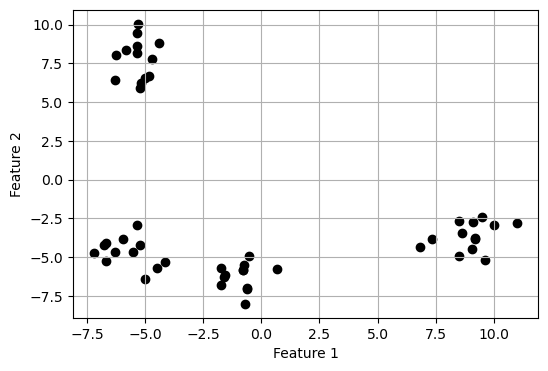

In [41]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X[:, 0],
    X[:, 1],
    color='black'
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

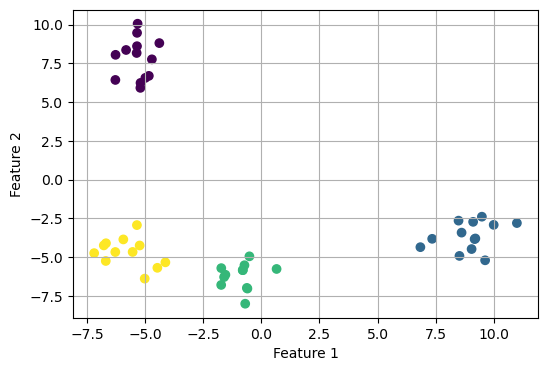

In [42]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

clusters: [[0, 2, 5, 10, 18, 21, 27, 31, 36, 40, 46, 49], [7, 8, 11, 14, 17, 38, 39, 41, 42, 44, 45, 48], [1, 3, 4, 9, 12, 23, 26, 29, 32, 34, 37, 43, 47], [6, 13, 15, 16, 19, 20, 22, 24, 25, 28, 30, 33, 35]]


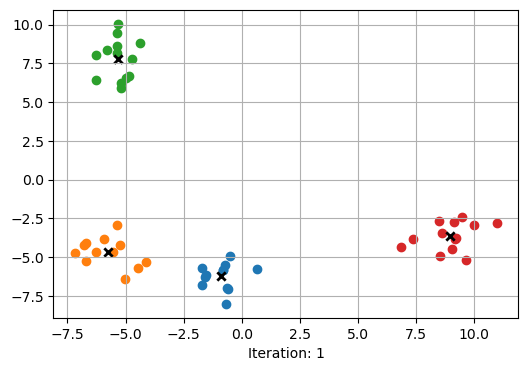

clusters: [[0, 2, 5, 10, 18, 21, 27, 31, 36, 40, 46, 49], [7, 8, 11, 14, 17, 38, 39, 41, 42, 44, 45, 48], [1, 3, 4, 9, 12, 23, 26, 29, 32, 34, 37, 43, 47], [6, 13, 15, 16, 19, 20, 22, 24, 25, 28, 30, 33, 35]]


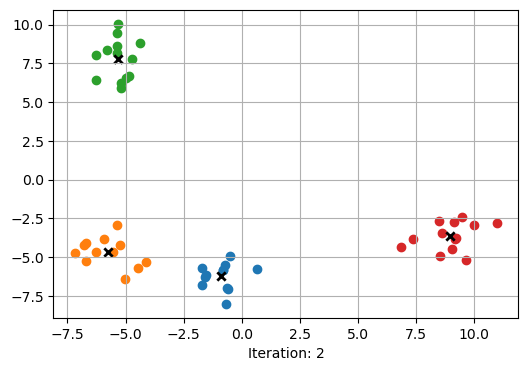

In [43]:
k = KMeans(
    K=n_clusters,
    max_iters=150,
    plot_steps=True,
    random_state=3
)

y_pred = k.fit(X)

In [44]:
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

ari = adjusted_rand_score(y, y_pred)

nmi = normalized_mutual_info_score(
    y,
    y_pred
)

print(f"ARI: {ari:.2f}")
print(f"NMI: {nmi:.2f}")

ARI: 1.00
NMI: 1.00


In [45]:
X = np.array([
    # Face outline
    [-5,0],[-4.9,1],[-4.7,2],[-4.3,3],[-3.7,3.9],
    [-3,4.5],[-2,4.8],[-1,5],[0,5],
    [1,5],[2,4.8],[3,4.5],[3.7,3.9],
    [4.3,3],[4.7,2],[4.9,1],[5,0],

    [4.9,-1],[4.7,-2],[4.3,-3],[3.7,-3.9],
    [3,-4.5],[2,-4.8],[1,-5],[0,-5],
    [-1,-5],[-2,-4.8],[-3,-4.5],[-3.7,-3.9],
    [-4.3,-3],[-4.7,-2],[-4.9,-1],

    # Left eye - dense cluster
    [-2.7,2.5],[-2.6,2.7],[-2.5,2.9],[-2.3,3.0],
    [-2.1,2.9],[-2.0,2.7],
    [-2.0,2.5],[-2.1,2.3],[-2.3,2.2],
    [-2.5,2.3],[-2.7,2.5],

    # Right eye - dense cluster
    [2.0,2.5],[2.0,2.7],[2.1,2.9],[2.3,3.0],
    [2.5,2.9],[2.6,2.7],
    [2.7,2.5],[2.5,2.3],[2.3,2.2],
    [2.1,2.3],[2.0,2.5],

    # Smile - dense curved cluster
    [-3,-1],[-2.8,-1.4],[-2.5,-1.8],[-2.2,-2.1],
    [-1.8,-2.4],[-1.4,-2.7],
    [-1,-2.9],[-0.5,-3.1],[0,-3.2],
    [0.5,-3.1],[1,-2.9],[1.4,-2.7],
    [1.8,-2.4],[2.2,-2.1],[2.5,-1.8],
    [2.8,-1.4],[3,-1]
])

y = np.array(
    [0]*32 +
    [1]*11 +
    [2]*11 +
    [3]*17
)

n_clusters = len(np.unique(y))

print(f'X.shape: {X.shape}')
print(f'y.shape: {y.shape}')
print(f'n_clusters: {n_clusters}')

X.shape: (71, 2)
y.shape: (71,)
n_clusters: 4


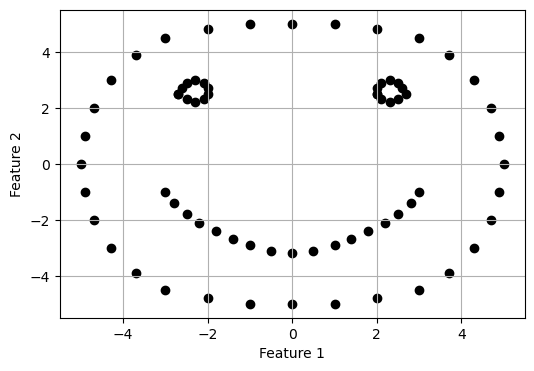

In [46]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X[:, 0],
    X[:, 1],
    color='black'
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

clusters: [[20, 21, 22, 23, 24, 25, 26, 27, 28, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67], [8, 9, 10, 11, 12, 13], [5, 6, 7, 14, 15, 16, 17, 18, 19, 34, 35, 36, 37, 38, 39, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 68, 69, 70], [0, 1, 2, 3, 4, 29, 30, 31, 32, 33, 40, 41, 42]]


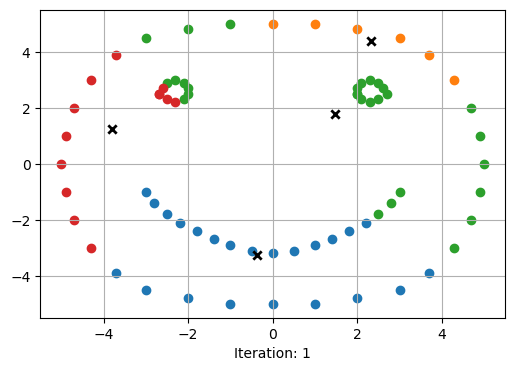

clusters: [[19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68], [7, 8, 9, 10, 11, 12, 13, 46, 47], [14, 15, 16, 17, 18, 43, 44, 45, 48, 49, 50, 51, 52, 53, 69, 70], [0, 1, 2, 3, 4, 5, 6, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 54, 55]]


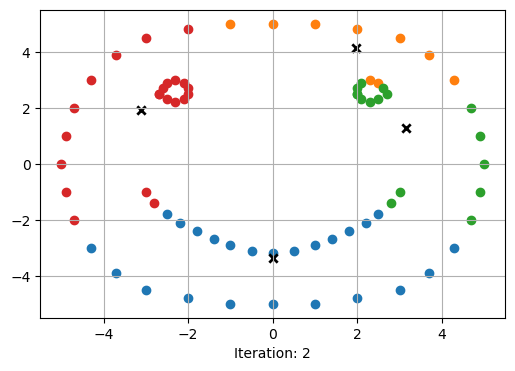

clusters: [[19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68], [7, 8, 9, 10, 11, 12, 43, 44, 45, 46, 47, 53], [13, 14, 15, 16, 17, 18, 48, 49, 50, 51, 52, 69, 70], [0, 1, 2, 3, 4, 5, 6, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 54, 55]]


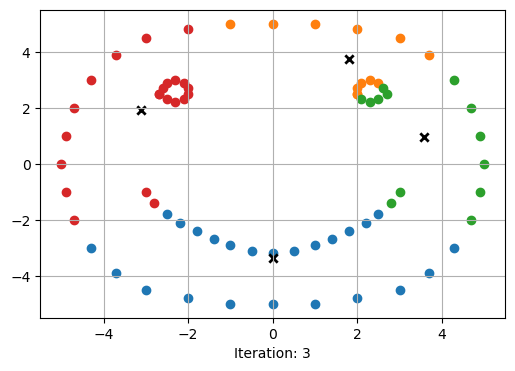

clusters: [[20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68], [7, 8, 9, 10, 11, 12, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [13, 14, 15, 16, 17, 18, 19, 69, 70], [0, 1, 2, 3, 4, 5, 6, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 54, 55]]


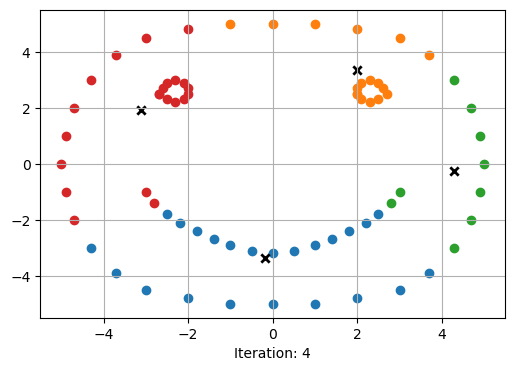

clusters: [[21, 22, 23, 24, 25, 26, 27, 28, 29, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67], [7, 8, 9, 10, 11, 12, 13, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [14, 15, 16, 17, 18, 19, 20, 68, 69, 70], [0, 1, 2, 3, 4, 5, 6, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 54]]


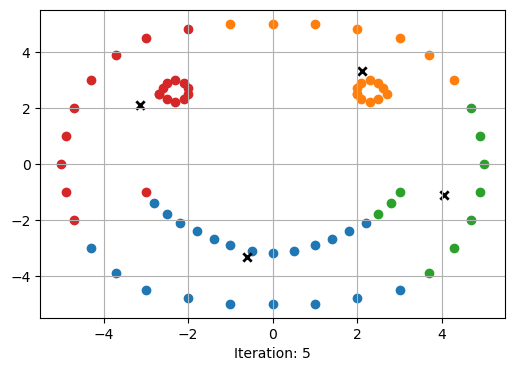

clusters: [[22, 23, 24, 25, 26, 27, 28, 29, 30, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66], [7, 8, 9, 10, 11, 12, 13, 14, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [15, 16, 17, 18, 19, 20, 21, 67, 68, 69, 70], [0, 1, 2, 3, 4, 5, 6, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 54]]


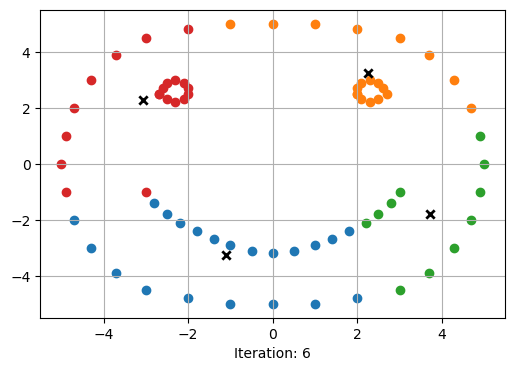

clusters: [[22, 23, 24, 25, 26, 27, 28, 29, 30, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64], [8, 9, 10, 11, 12, 13, 14, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [15, 16, 17, 18, 19, 20, 21, 65, 66, 67, 68, 69, 70], [0, 1, 2, 3, 4, 5, 6, 7, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42]]


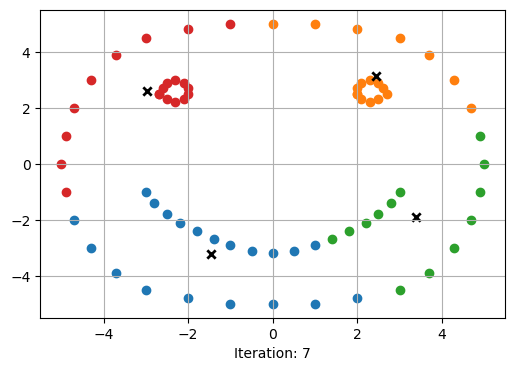

clusters: [[23, 24, 25, 26, 27, 28, 29, 30, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64], [8, 9, 10, 11, 12, 13, 14, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [15, 16, 17, 18, 19, 20, 21, 22, 65, 66, 67, 68, 69, 70], [0, 1, 2, 3, 4, 5, 6, 7, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42]]


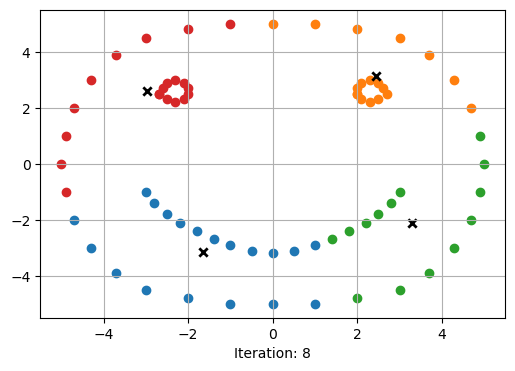

clusters: [[23, 24, 25, 26, 27, 28, 29, 30, 31, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63], [8, 9, 10, 11, 12, 13, 14, 15, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [16, 17, 18, 19, 20, 21, 22, 64, 65, 66, 67, 68, 69, 70], [0, 1, 2, 3, 4, 5, 6, 7, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42]]


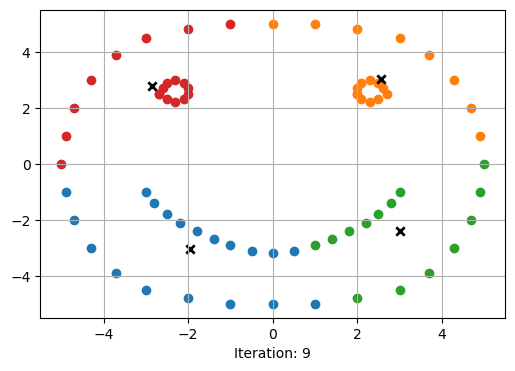

clusters: [[24, 25, 26, 27, 28, 29, 30, 31, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63], [8, 9, 10, 11, 12, 13, 14, 15, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [16, 17, 18, 19, 20, 21, 22, 23, 64, 65, 66, 67, 68, 69, 70], [0, 1, 2, 3, 4, 5, 6, 7, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42]]


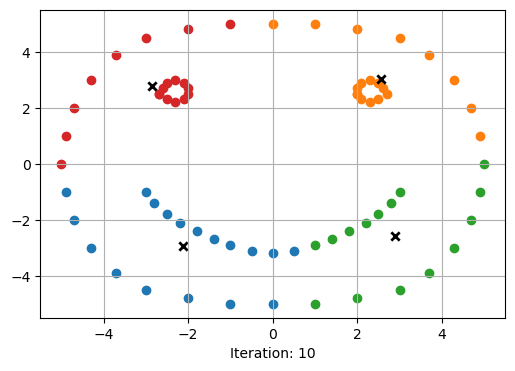

clusters: [[24, 25, 26, 27, 28, 29, 30, 31, 54, 55, 56, 57, 58, 59, 60, 61, 62], [8, 9, 10, 11, 12, 13, 14, 15, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [16, 17, 18, 19, 20, 21, 22, 23, 63, 64, 65, 66, 67, 68, 69, 70], [0, 1, 2, 3, 4, 5, 6, 7, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42]]


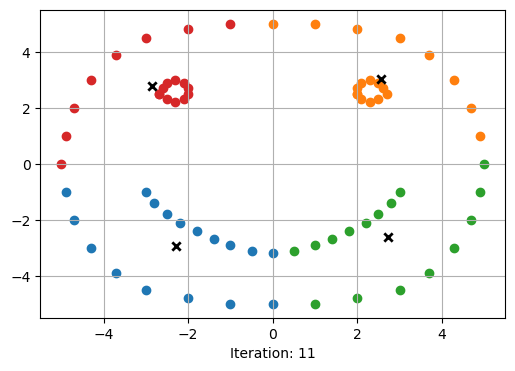

clusters: [[24, 25, 26, 27, 28, 29, 30, 31, 54, 55, 56, 57, 58, 59, 60, 61, 62], [8, 9, 10, 11, 12, 13, 14, 15, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [16, 17, 18, 19, 20, 21, 22, 23, 63, 64, 65, 66, 67, 68, 69, 70], [0, 1, 2, 3, 4, 5, 6, 7, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42]]


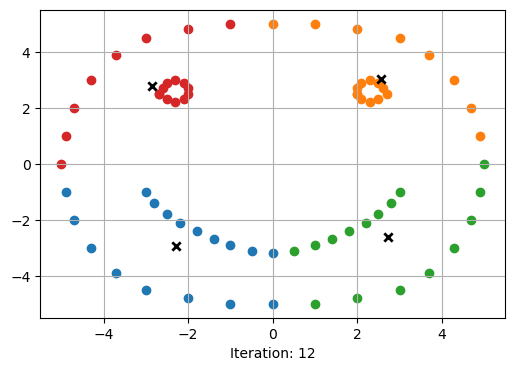

In [47]:
k = KMeans(
    K=n_clusters,
    max_iters=150,
    plot_steps=True,
    random_state=3
)

y_pred = k.fit(X)

In [48]:
ari = adjusted_rand_score(y, y_pred)

nmi = normalized_mutual_info_score(
    y,
    y_pred
)

print(f"ARI: {ari:.2f}")
print(f"NMI: {nmi:.2f}")

ARI: 0.22
NMI: 0.45


In [49]:
from sklearn.datasets import load_iris

iris = load_iris()

X = iris.data
y = iris.target

n_clusters = len(np.unique(y))

print(f'X.shape: {X.shape}')
print(f'y.shape: {y.shape}')
print(f'n_clusters: {n_clusters}')

X.shape: (150, 4)
y.shape: (150,)
n_clusters: 3


In [50]:
org_clusters = [[] for _ in range(n_clusters)]

for idx, sample in enumerate(X):
    org_clusters[y[idx]].append(idx)

print(org_clusters)

[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49], [50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99], [100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149]]


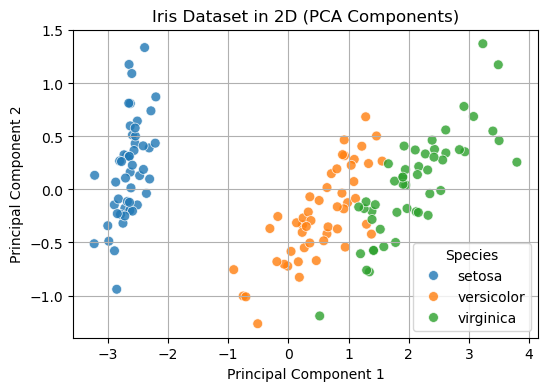

In [51]:
from sklearn.decomposition import PCA
import seaborn as sns

pca_viz = PCA(
    n_components=2,
    random_state=42
)

X_pca_viz = pca_viz.fit_transform(X)

plt.figure(figsize=(6, 4))

sns.scatterplot(
    x=X_pca_viz[:, 0],
    y=X_pca_viz[:, 1],
    hue=iris.target_names[y],
    palette='tab10',
    s=50,
    alpha=0.8
)

plt.title(
    'Iris Dataset in 2D (PCA Components)'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.grid(True)

plt.legend(title='Species')

plt.show()

In [52]:
k = KMeans(
    K=n_clusters,
    max_iters=150,
    plot_steps=False,
    random_state=3
)

y_pred = k.fit(X)

clusters: [[51, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 78, 79, 80, 81, 82, 83, 84, 85, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 101, 106, 113, 114, 119, 121, 123, 126, 127, 133, 134, 138, 142, 146, 149], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49], [50, 52, 76, 77, 86, 100, 102, 103, 104, 105, 107, 108, 109, 110, 111, 112, 115, 116, 117, 118, 120, 122, 124, 125, 128, 129, 130, 131, 132, 135, 136, 137, 139, 140, 141, 143, 144, 145, 147, 148]]
clusters: [[51, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 101, 106, 113, 114, 119, 121, 123, 126, 127, 133, 138, 142, 146, 149], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 2

In [53]:
ari = adjusted_rand_score(y, y_pred)

nmi = normalized_mutual_info_score(
    y,
    y_pred
)

print(f"ARI: {ari:.2f}")
print(f"NMI: {nmi:.2f}")

ARI: 0.72
NMI: 0.74


In [54]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

from scipy.cluster.hierarchy import dendrogram, linkage

np.random.seed(20)

In [55]:
X, y = make_blobs(
    centers=4,
    n_samples=50,
    n_features=2,
    shuffle=True,
    random_state=272
)

n_clusters = len(np.unique(y))

print(f'X.shape: {X.shape}')
print(f'y.shape: {y.shape}')
print(f'n_clusters: {n_clusters}')

X.shape: (50, 2)
y.shape: (50,)
n_clusters: 4


In [56]:
X[0:10]

array([[-1.7214614 , -5.70633574],
       [-5.81623847,  8.36037108],
       [-0.79582536, -5.8347217 ],
       [-4.9868333 ,  6.56176804],
       [-5.32085737, 10.05336814],
       [-0.51149662, -4.94563944],
       [10.99348975, -2.79948944],
       [-6.2803617 , -4.66686882],
       [-5.01498597, -6.38332099],
       [-5.20164013,  5.91755293]])

In [57]:
y[0:10]

array([2, 0, 2, 0, 0, 2, 1, 3, 3, 0])

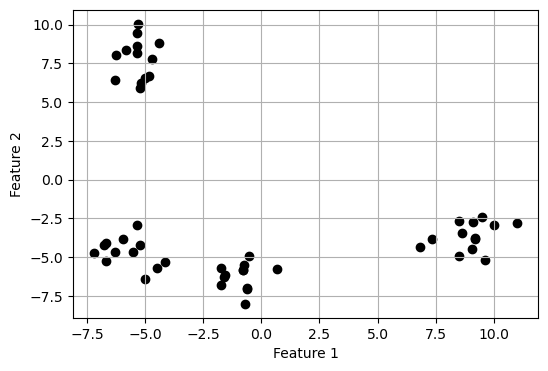

In [58]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X[:, 0],
    X[:, 1],
    color='black'
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

In [59]:
model = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage='ward',
    metric='euclidean'
)

y_pred = model.fit_predict(X)

print(f'Predicted clusters: {y_pred}')

Predicted clusters: [3 0 3 0 0 3 2 1 1 0 3 1 0 2 1 2 2 1 3 2 2 3 2 0 2 2 0 3 2 0 2 3 0 2 0 2 3
 0 1 1 3 1 1 0 1 1 3 0 1 3]


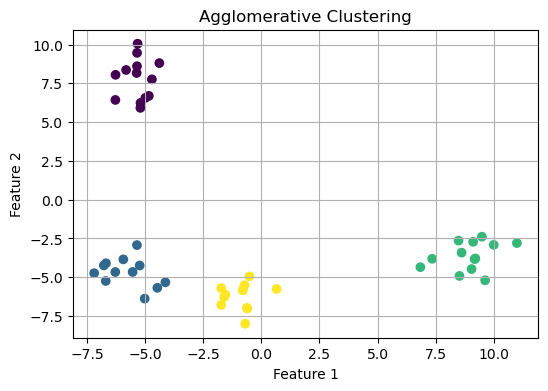

In [60]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y_pred
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Agglomerative Clustering')
plt.grid(True)
plt.show()

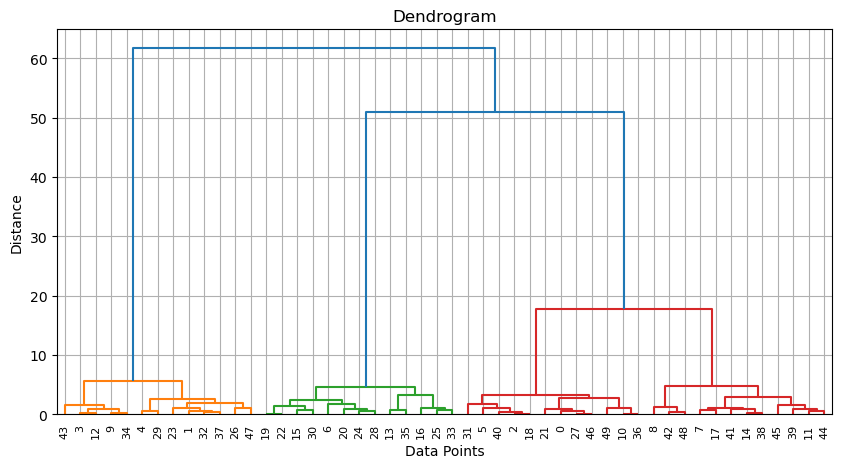

In [61]:
Z = linkage(
    X,
    method='ward',
    metric='euclidean'
)

plt.figure(figsize=(10, 5))

dendrogram(Z)

plt.title('Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Distance')

plt.grid(True)
plt.show()

In [62]:
ari = adjusted_rand_score(y, y_pred)

nmi = normalized_mutual_info_score(
    y,
    y_pred
)

print(f"ARI: {ari:.2f}")
print(f"NMI: {nmi:.2f}")

ARI: 1.00
NMI: 1.00


In [63]:
model = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage='ward',
    metric='euclidean'
)

y_pred = model.fit_predict(X)

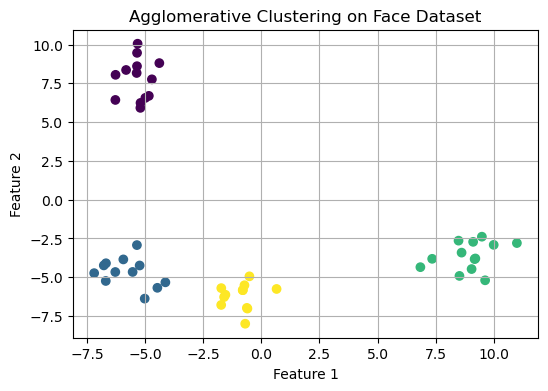

In [64]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y_pred
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Agglomerative Clustering on Face Dataset')

plt.grid(True)
plt.show()

In [65]:
from sklearn.datasets import load_iris

iris = load_iris()

X = iris.data
y = iris.target

n_clusters = len(np.unique(y))

print(f'X.shape: {X.shape}')
print(f'y.shape: {y.shape}')
print(f'n_clusters: {n_clusters}')

X.shape: (150, 4)
y.shape: (150,)
n_clusters: 3


In [66]:
model = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage='ward',
    metric='euclidean'
)

y_pred = model.fit_predict(X)

In [67]:
ari = adjusted_rand_score(y, y_pred)

nmi = normalized_mutual_info_score(
    y,
    y_pred
)

print(f"ARI: {ari:.2f}")
print(f"NMI: {nmi:.2f}")

ARI: 0.73
NMI: 0.77
